# Model Tabular dan Normalisasi Sensor

Klasifikasi cognitive load Low, Medium, dan High dari fitur eye tracking dan HRV. Window 15, 25, dan 45 detik dibandingkan dengan pembagian data yang sama.

## Konfigurasi

Dataset dan hasil eksperimen disimpan pada Google Drive. Tentukan lokasi proyek dan folder run bila melanjutkan eksperimen yang terputus.

In [1]:
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Penelitian-Adaptive-IDE")
DATASET_ROOT = PROJECT_ROOT / "Dataset" / "v2_session_phase"
RESUME_DIR = None
EXPERIMENT = "exp01"

In [2]:
import importlib.metadata as _metadata
import importlib.util as _import_util
import subprocess
import sys

if sys.version_info < (3, 12):
    raise RuntimeError("Gunakan runtime Colab dengan Python 3.12 atau lebih baru.")

# Versi dependency dicatat bersama hasil eksperimen.
_required = {
    "numpy": "2.5.1",
    "pandas": "3.0.3",
    "scipy": "1.18.0",
    "scikit-learn": "1.9.1",
    "matplotlib": "3.11.0",
    "cloudpickle": "3.1.3",
}
if EXPERIMENT == "exp01":
    _required.update({"xgboost": "3.4.1", "catboost": "1.2.10"})
_imports = {"scikit-learn": "sklearn", "imbalanced-learn": "imblearn"}
_changes = []
_restart = False
_current: str | None
for _name, _version in _required.items():
    try:
        _current = _metadata.version(_name)
    except _metadata.PackageNotFoundError:
        _current = None
    if _current != _version:
        _changes.append(f"{_name}=={_version}")
        _restart = _restart or _imports.get(_name, _name) in sys.modules
if _changes:
    print("Menyiapkan dependency:", ", ".join(_changes))
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "--quiet", *_changes]
    )  # nosec B603
    if _restart:
        raise RuntimeError(
            "Dependency diperbarui. Pilih Runtime > Restart session, lalu Run all kembali."
        )
if EXPERIMENT == "exp02" and _import_util.find_spec("torch") is None:
    raise RuntimeError(
        "PyTorch tidak tersedia. Gunakan runtime Colab standar yang sudah menyertakan PyTorch."
    )

try:
    _in_colab = _import_util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    _in_colab = False
if _in_colab:
    from google.colab import drive

    drive.mount("/content/drive")

print("Dependency siap. Path proyek:", PROJECT_ROOT)

Mounted at /content/drive
Dependency siap. Path proyek: /content/drive/MyDrive/Penelitian-Adaptive-IDE


In [3]:
import copy
import hashlib
import io
import json
import platform
import random
import tempfile
import time
from datetime import UTC, datetime
from functools import partial
from importlib import metadata
from pathlib import Path
from typing import Any

import cloudpickle
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

LABELS = ["Low", "Medium", "High"]
SEED = 42
CODE_VERSION = "batch04-2.0.0"
SENSOR_FEATURES = [
    "rmssd_ms",
    "sdnn_ms",
    "rmssd_baseline_ratio",
    "blink_count",
    "blink_rate_per_minute",
    "ear_left_mean",
    "ear_left_std",
    "ear_right_mean",
    "ear_right_std",
    "iris_size_estimate_mean",
    "iris_size_estimate_std",
    "iris_size_delta_mean",
    "iris_size_delta_std",
    "head_pitch_mean",
    "head_pitch_std",
    "head_yaw_mean",
    "head_yaw_std",
    "gaze_x_norm_mean",
    "gaze_x_norm_std",
    "gaze_y_norm_mean",
    "gaze_y_norm_std",
    "eye_state_fixation_ratio",
    "eye_state_saccade_ratio",
    "eye_state_transition_ratio",
    "eye_state_unclassified_ratio",
    "eye_state_other_ratio",
]
EYE_FEATURES = [
    f
    for f in SENSOR_FEATURES
    if f
    not in {
        "rmssd_ms",
        "sdnn_ms",
        "rmssd_baseline_ratio",
        "blink_count",
        "eye_state_other_ratio",
    }
]
GROUPS = {
    "eye": EYE_FEATURES,
    "hrv": ["rmssd_ms", "sdnn_ms"],
    "fusion": ["rmssd_ms", "sdnn_ms"] + EYE_FEATURES,
}


def canonical(value):
    return json.dumps(value, sort_keys=True, separators=(",", ":"), allow_nan=False)


def digest(value):
    return hashlib.sha256(canonical(value).encode()).hexdigest()


try:
    from IPython.display import display
except ImportError:
    display = print

IMPLEMENTATION_HASH = "7aa1c28983ebbf362e9fc665f713dfc4a36bbb20db3980c2252d1464a87ace2d"

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import ParameterGrid
from sklearn.svm import SVC
from sklearn.utils.class_weight import compute_sample_weight

## Dataset dan Pembagian Data

Test menggunakan blok waktu tetap dari evaluasi sebelumnya. Sisa data dipisahkan menjadi Train dan validation akhir. Di dalam Train, lima fold bergantian menjadi validation internal, sehingga setiap baris mendapat satu prediksi out-of-fold.

Blok berdurasi 120 detik tidak dipecah antarbagian. Purge 45 detik mencegah dukungan sensor yang overlap masuk ke bagian berbeda, termasuk antarwindow. Stratifikasi memperhitungkan kelas dan sesi bila jumlah blok mencukupi. Identitas, fase, soal, dan timestamp tidak menjadi predictor classifier. Evaluasi ini bersifat internal pada dataset yang telah digunakan sebelumnya.

In [4]:
def prepare_views(frames):
    """Split metadata-only; tidak menggunakan nilai fitur untuk penempatan blok."""
    if set(frames) != {15, 25, 45}:
        raise ValueError("Ketiga CSV window 15, 25, dan 45 detik harus tersedia.")
    clean: dict[int, Any] = {}
    union: dict[tuple[str, int], str] = {}
    anchors: dict[str, int] = {}
    people: dict[str, str] = {}
    required = set(
        SENSOR_FEATURES
        + [
            "participant_id",
            "session_id",
            "window_start",
            "window_end",
            "window_seconds",
            "cognitive_load_label",
        ]
    )
    for window in (15, 25, 45):
        df = frames[window].copy()
        missing = required - set(df)
        if missing or df.empty:
            raise ValueError(
                f"Window {window}: kolom hilang {sorted(missing)} atau CSV kosong."
            )
        for field in ("session_id", "participant_id"):
            if df[field].isna().any() or df[field].astype(str).str.strip().eq("").any():
                raise ValueError(f"Window {window}: {field} kosong.")
            df[field] = df[field].astype(str)
        if not df["cognitive_load_label"].isin(LABELS).all():
            raise ValueError(f"Window {window}: label tidak dikenal atau kosong.")
        try:
            start = pd.to_datetime(
                df["window_start"], utc=True, errors="raise", format="ISO8601"
            )
            end = pd.to_datetime(
                df["window_end"], utc=True, errors="raise", format="ISO8601"
            )
            df["_start_ns"] = start.dt.as_unit("ns").astype("int64")
            df["_end_ns"] = end.dt.as_unit("ns").astype("int64")
        except (ValueError, TypeError) as exc:
            raise ValueError(f"Window {window}: timestamp tidak valid.") from exc
        if start.isna().any() or end.isna().any():
            raise ValueError("Timestamp kosong.")
        duration = (end - start).dt.total_seconds().to_numpy()
        if not np.allclose(duration, window, atol=0.001, rtol=0):
            raise ValueError(
                f"Window {window}: rentang timestamp bukan {window} detik."
            )
        if not pd.to_numeric(df["window_seconds"], errors="coerce").eq(window).all():
            raise ValueError(f"Window {window}: window_seconds tidak cocok.")
        if df.duplicated(["session_id", "_end_ns"]).any():
            raise ValueError(f"Window {window}: endpoint ganda.")
        for field in SENSOR_FEATURES:
            df[field] = pd.to_numeric(df[field], errors="coerce").replace(
                [np.inf, -np.inf], np.nan
            )
        df["_y"] = df["cognitive_load_label"].map(
            {label: i for i, label in enumerate(LABELS)}
        )
        df = df.sort_values(["session_id", "_end_ns"]).reset_index(drop=True)
        for row in df[
            [
                "session_id",
                "participant_id",
                "_start_ns",
                "_end_ns",
                "cognitive_load_label",
            ]
        ].itertuples(index=False, name=None):
            sid, person, first, last, label = row
            key = (sid, int(last))
            if key in union and union[key] != label:
                raise ValueError("Label endpoint bertentangan antarwindow.")
            if sid in people and people[sid] != person:
                raise ValueError("Satu session_id terhubung ke beberapa peserta.")
            people[sid] = person
            union[key] = label
            anchors[sid] = min(anchors.get(sid, int(first)), int(first))
        clean[window] = df

    blocks: dict[tuple[str, int], list[tuple[tuple[str, int], str]]] = {}
    for key, label in sorted(union.items()):
        block = (key[0], (key[1] - anchors[key[0]]) // 120_000_000_000)
        blocks.setdefault(block, []).append((key, label))
    buckets: dict[str, list[tuple[str, int]]] = {}
    for block, members in sorted(blocks.items()):
        counts: dict[str, int] = {}
        for _, label in members:
            counts[label] = counts.get(label, 0) + 1
        dominant = min(counts, key=lambda label: (-counts[label], label))
        buckets.setdefault(dominant, []).append(block)
    rng = random.Random(SEED)
    assignment = {}
    for label, group in sorted(buckets.items()):
        rng.shuffle(group)
        n = max(1, round(len(group) * 0.15))
        if len(group) < 3:
            raise ValueError("Blok terlalu sedikit untuk membentuk tiga bagian.")
        for i, block in enumerate(group):
            part = "test" if i < n else "validation" if i < 2 * n else "train"
            for key, _ in blocks[block]:
                assignment[key] = part

    def close_to(key, index):
        values = index.get(key[0], np.array([], dtype=np.int64))
        if not len(values):
            return False
        pos = np.searchsorted(values, key[1])
        return any(
            abs(int(values[j]) - key[1]) < 45_000_000_000
            for j in (pos - 1, pos)
            if 0 <= j < len(values)
        )

    def index_for(parts):
        index: dict[str, list[int]] = {}
        for sid, last in parts:
            index.setdefault(sid, []).append(last)
        return {
            sid: np.array(sorted(values), dtype=np.int64)
            for sid, values in index.items()
        }

    kept = {key: part for key, part in assignment.items() if part == "test"}
    test_index = index_for(kept)
    kept.update(
        {
            key: part
            for key, part in assignment.items()
            if part == "validation" and not close_to(key, test_index)
        }
    )
    held_index = index_for(kept)
    kept.update(
        {
            key: part
            for key, part in assignment.items()
            if part == "train" and not close_to(key, held_index)
        }
    )
    manifest = [
        {
            "session_id": key[0],
            "end_ns": key[1],
            "assigned": assignment[key],
            "split": kept.get(key, "purged"),
        }
        for key in sorted(union)
    ]
    summary = []
    for window, df in clean.items():
        df["_split"] = [
            kept.get((sid, int(last)), "purged")
            for sid, last in zip(df["session_id"], df["_end_ns"], strict=True)
        ]
        for part in ("train", "validation", "test", "purged"):
            subset = df[df["_split"] == part]
            class_counts = subset["cognitive_load_label"].value_counts()
            if part != "purged" and not set(LABELS).issubset(class_counts.index):
                raise ValueError(
                    f"Window {window}: {part} tidak mempunyai ketiga kelas."
                )
            summary.append(
                {
                    "window_seconds": window,
                    "split": part,
                    "rows": len(subset),
                    **{label: int(class_counts.get(label, 0)) for label in LABELS},
                }
            )
    return clean, manifest, pd.DataFrame(summary)


N_FOLDS = 5
NORMALIZATIONS = ("global", "session_center", "session_zscore")
GROUPS["nonspatial"] = GROUPS["hrv"] + [
    c
    for c in EYE_FEATURES
    if c == "blink_rate_per_minute" or c.startswith(("ear_", "iris_"))
]
RELATIVE_FEATURES = ["hrv_ratio", "ear_relative_gap", "ear_variation", "iris_variation"]
GROUPS["relative"] = GROUPS["fusion"] + RELATIVE_FEATURES


def purge_against(frame, held):
    """Remove training endpoints with overlapping conservative 45-second support."""
    keep = []
    for sid, subset in frame.groupby("session_id", sort=True):
        times = np.sort(held.loc[held.session_id.eq(sid), "_end_ns"].to_numpy())
        ends = subset._end_ns.to_numpy()
        if not len(times):
            keep.extend(subset.index)
            continue
        pos = np.searchsorted(times, ends)
        left = times[np.maximum(pos - 1, 0)]
        right = times[np.minimum(pos, len(times) - 1)]
        good = (np.abs(ends - left) >= 45_000_000_000) & (
            np.abs(ends - right) >= 45_000_000_000
        )
        keep.extend(subset.index[good])
    return frame.loc[sorted(keep)]


def block_folds(frame):
    """Balance session/class strata where supported, without splitting time blocks."""
    if frame._block.nunique() < N_FOLDS:
        raise ValueError("Blok training terlalu sedikit untuk lima fold.")
    counts = frame.groupby(["session_id", "cognitive_load_label"])._block.nunique()
    strata = np.array(
        [
            f"session::{sid}::{label}"
            if counts[(sid, label)] >= N_FOLDS
            else f"global::{label}"
            for sid, label in zip(
                frame.session_id, frame.cognitive_load_label, strict=True
            )
        ],
        dtype=object,
    )
    for label in LABELS:
        rare = int((strata == f"global::{label}").sum())
        if 0 < rare < N_FOLDS:
            strata[frame.cognitive_load_label.eq(label).to_numpy()] = f"global::{label}"
    return list(
        StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=42).split(
            np.zeros(len(frame)), strata, frame._block
        )
    )


def endpoint_keys(frame):
    return set(zip(frame.session_id, frame._end_ns.astype(int), strict=True))


def prepare_experiment(frames):
    views, legacy_outer, _ = prepare_views(frames)
    combined = pd.concat(views.values(), ignore_index=True)
    anchors = combined.groupby("session_id")._start_ns.min()
    union = (
        combined.drop_duplicates(["session_id", "_end_ns"])
        .sort_values(["session_id", "_end_ns"])
        .copy()
    )
    union["_block"] = pd.factorize(
        pd.MultiIndex.from_arrays(
            [
                union.session_id,
                (union._end_ns - union.session_id.map(anchors)) // 120_000_000_000,
            ]
        ),
        sort=True,
    )[0]
    test = union[union._split.eq("test")]
    development = purge_against(union[~union._split.eq("test")], test)
    train_idx, selection_idx = block_folds(development)[0]
    selection = development.iloc[selection_idx]
    train = purge_against(development.iloc[train_idx], selection)
    main = {
        **dict.fromkeys(endpoint_keys(train), "train"),
        **dict.fromkeys(endpoint_keys(selection), "validation"),
        **dict.fromkeys(endpoint_keys(test), "test"),
    }
    folds, monitors = [], []
    for fitting_idx, scoring_idx in block_folds(train):
        scoring = train.iloc[scoring_idx]
        fitting = purge_against(train.iloc[fitting_idx], scoring)
        monitor_fit_idx, monitor_idx = block_folds(fitting)[0]
        monitor = fitting.iloc[monitor_idx]
        monitor_fit = purge_against(fitting.iloc[monitor_fit_idx], monitor)
        folds.append(
            {
                **dict.fromkeys(endpoint_keys(fitting), "train"),
                **dict.fromkeys(endpoint_keys(scoring), "validation"),
            }
        )
        monitors.append(
            {
                **dict.fromkeys(endpoint_keys(monitor_fit), "fit"),
                **dict.fromkeys(endpoint_keys(monitor), "monitor"),
            }
        )
    summaries = []
    for window, view in views.items():
        keys = list(zip(view.session_id, view._end_ns.astype(int), strict=True))
        view["_split"] = [main.get(k, "purged") for k in keys]
        view["_block"] = list(
            zip(
                view.session_id,
                (
                    (view._end_ns - view.session_id.map(anchors)) // 120_000_000_000
                ).astype(int),
                strict=True,
            )
        )
        for fold in range(N_FOLDS):
            view[f"_fold_{fold}"] = [folds[fold].get(k, "purged") for k in keys]
            view[f"_monitor_{fold}"] = [monitors[fold].get(k, "purged") for k in keys]
        partitions = [
            ("outer", -1, part, outer_frame(view, part))
            for part in ("train", "validation", "test", "purged")
        ]
        for fold in range(N_FOLDS):
            partitions.extend(
                ("inner", fold, part, fold_frame(view, fold, part))
                for part in ("train", "validation")
            )
            partitions.extend(
                ("monitor", fold, part, view[view[f"_monitor_{fold}"].eq(part)])
                for part in ("fit", "monitor")
            )
        for level, fold, part, sub in partitions:
            counts = sub.cognitive_load_label.value_counts()
            if part != "purged" and not set(LABELS).issubset(counts.index):
                raise ValueError(
                    f"Window {window}, {level}/{fold}/{part}: kelas tidak lengkap."
                )
            summaries.append(
                {
                    "window": window,
                    "level": level,
                    "fold": fold,
                    "split": part,
                    "rows": len(sub),
                    **{label: int(counts.get(label, 0)) for label in LABELS},
                }
            )
        hits = sum(
            view[f"_fold_{i}"].eq("validation").astype(int) for i in range(N_FOLDS)
        )
        if not hits.loc[view._split.eq("train")].eq(1).all():
            raise ValueError("Cakupan out-of-fold tidak tepat satu kali.")

    def manifest_rows(assignment):
        return [
            {
                "session_id": sid,
                "end_ns": int(last),
                "split": assignment.get((sid, int(last)), "purged"),
            }
            for sid, last in union[["session_id", "_end_ns"]].itertuples(
                index=False, name=None
            )
        ]

    manifest = {
        "schema_version": 2,
        "seed": 42,
        "n_folds": N_FOLDS,
        "block_seconds": 120,
        "support_seconds": 45,
        "legacy_outer": legacy_outer,
        "outer": manifest_rows(main),
        "inner": [manifest_rows(a) for a in folds],
        "monitor": [manifest_rows(a) for a in monitors],
    }
    return views, manifest, pd.DataFrame(summaries)


def outer_frame(view, part):
    return view.loc[view._split.eq(part)].reset_index(drop=True)


def fold_frame(view, fold, part):
    if part == "test":
        return outer_frame(view, "test")
    return view.loc[view[f"_fold_{fold}"].eq(part)].reset_index(drop=True)


def read_datasets(dataset_root):
    frames, hashes = {}, {}
    for window in (15, 25, 45):
        payload = (
            Path(dataset_root) / f"window_{window}s_step_5s" / "good_acceptable.csv"
        ).read_bytes()
        hashes[str(window)] = hashlib.sha256(payload).hexdigest()
        frames[window] = pd.read_csv(io.BytesIO(payload))
    views, manifest, summary = prepare_experiment(frames)
    return views, manifest, summary, hashes

In [5]:
views, split_manifest, split_counts, dataset_hashes = read_datasets(DATASET_ROOT)
display(split_counts[split_counts.level.eq("outer")])
display(split_counts[split_counts.level.eq("inner")])
distribution = pd.DataFrame(
    {
        f"{w}s": d.cognitive_load_label.value_counts().reindex(LABELS)
        for w, d in views.items()
    }
)
display(distribution)

,window,level,fold,split,rows,Low,Medium,High
0,15,outer,-1,train,2069,599,764,706
1,15,outer,-1,validation,560,168,198,194
2,15,outer,-1,test,464,141,173,150
3,15,outer,-1,purged,486,154,131,201
24,25,outer,-1,train,1845,546,663,636
25,25,outer,-1,validation,489,153,157,179
26,25,outer,-1,test,423,133,161,129
27,25,outer,-1,purged,457,152,112,193
48,45,outer,-1,train,1444,492,463,489
49,45,outer,-1,validation,373,137,88,148


,window,level,fold,split,rows,Low,Medium,High
4,15,inner,0,train,1494,424,582,488
5,15,inner,0,validation,412,125,135,152
8,15,inner,1,train,1480,433,512,535
9,15,inner,1,validation,407,123,165,119
12,15,inner,2,train,1455,447,512,496
13,15,inner,2,validation,424,111,168,145
16,15,inner,3,train,1495,450,533,512
17,15,inner,3,validation,417,118,158,141
20,15,inner,4,train,1479,433,542,504
21,15,inner,4,validation,409,122,138,149


,15s,25s,45s
cognitive_load_label,,,
Low,1062,984,908
Medium,1266,1093,728
High,1251,1137,891


## Prapemrosesan dan Representasi Sensor

Skala global, pemusatan per sesi, dan standardisasi per sesi dibandingkan sebagai cabang terpisah. Imputer, scaler, serta acuan sesi hanya dipelajari dari training. Sesi tanpa acuan menggunakan statistik global training.

Fusion memakai 23 fitur; nonspatial memakai 11 fitur tanpa posisi gaze, orientasi kepala, dan rasio keadaan mata. Empat fitur relatif mengukur hubungan RMSSD–SDNN, perbedaan EAR, variasi EAR, dan variasi ukuran iris. Pembagi mendekati nol diperlakukan sebagai missing value. Nilai negatif hasil pemusatan tetap sah.

In [6]:
def raw_sensor_input(frame, columns):
    x = (
        frame[columns]
        .apply(pd.to_numeric, errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .reset_index(drop=True)
    )
    for name in ("rmssd_ms", "sdnn_ms", "rmssd_baseline_ratio"):
        if name in x:
            x.loc[x[name] < 0, name] = np.nan
    return x


def sensor_features(frame, columns):
    requested = list(columns)
    if not set(requested).intersection(RELATIVE_FEATURES):
        return raw_sensor_input(frame, requested)
    dependencies = {
        "hrv_ratio": ["rmssd_ms", "sdnn_ms"],
        "ear_relative_gap": ["ear_left_mean", "ear_right_mean"],
        "ear_variation": [
            "ear_left_mean",
            "ear_right_mean",
            "ear_left_std",
            "ear_right_std",
        ],
        "iris_variation": ["iris_size_estimate_mean", "iris_size_estimate_std"],
    }
    needed = [c for c in requested if c not in RELATIVE_FEATURES]
    for name in requested:
        needed.extend(dependencies.get(name, []))
    raw = raw_sensor_input(frame, list(dict.fromkeys(needed)))

    def divide(numerator, denominator):
        return numerator / denominator.where(denominator.abs() > 1e-6)

    derived = {}
    if "hrv_ratio" in requested:
        derived["hrv_ratio"] = divide(raw.rmssd_ms, raw.sdnn_ms)
    if {"ear_relative_gap", "ear_variation"}.intersection(requested):
        ear_sum = raw.ear_left_mean.abs() + raw.ear_right_mean.abs()
        if "ear_relative_gap" in requested:
            derived["ear_relative_gap"] = divide(
                2 * (raw.ear_left_mean - raw.ear_right_mean), ear_sum
            )
        if "ear_variation" in requested:
            derived["ear_variation"] = divide(
                raw.ear_left_std + raw.ear_right_std, ear_sum
            )
    if "iris_variation" in requested:
        derived["iris_variation"] = divide(
            raw.iris_size_estimate_std, raw.iris_size_estimate_mean.abs()
        )
    return raw.assign(**derived)[requested].replace([np.inf, -np.inf], np.nan)


class SessionPreprocessor:
    def __init__(self, columns, normalization="global", selector="all"):
        self.columns = list(columns)
        self.normalization = normalization
        self.selector = selector

    def _normalize(self, frame):
        x = sensor_features(frame, self.columns)
        if self.normalization != "global":
            sid = frame["session_id"].astype(str)
            center = (
                self.centers_.reindex(sid)
                .reset_index(drop=True)
                .fillna(self.global_center_)
            )
            x = x - center
            if self.normalization == "session_zscore":
                scale = (
                    self.scales_.reindex(sid)
                    .reset_index(drop=True)
                    .fillna(self.global_scale_)
                )
                x = x / scale
        # Negative HRV after centering is valid. Physical checks belong above.
        return x

    def fit(self, frame, y=None):
        if self.normalization not in NORMALIZATIONS or self.selector not in (
            "all",
            "mi8",
        ):
            raise ValueError("Normalisasi/seleksi fitur tidak dikenal.")
        x = sensor_features(frame, self.columns)
        sid = frame["session_id"].astype(str).to_numpy()
        self.global_center_ = x.mean().fillna(0)
        self.global_scale_ = x.std(ddof=0).where(lambda s: s > 1e-10, 1).fillna(1)
        self.centers_ = (
            x.assign(_session=sid)
            .groupby("_session")
            .mean()
            .fillna(self.global_center_)
        )
        self.scales_ = x.assign(_session=sid).groupby("_session").std(ddof=0)
        self.scales_ = self.scales_.where(self.scales_ > 1e-10).fillna(
            self.global_scale_
        )
        steps = [
            ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("scaler", StandardScaler()),
        ]
        if self.selector == "mi8":
            steps.append(
                (
                    "selector",
                    SelectKBest(
                        partial(mutual_info_classif, random_state=42),
                        k=min(8, len(self.columns)),
                    ),
                )
            )
        self.pipeline_ = Pipeline(steps).fit(self._normalize(frame), y)
        return self

    def transform(self, frame):
        result = self.pipeline_.transform(self._normalize(frame))
        if not np.isfinite(result).all():
            raise ValueError("Hasil preprocessing nonfinite.")
        return result

    def fit_transform(self, frame, y=None):
        return self.fit(frame, y).transform(frame)


def metric_labels(y, predicted):
    return {
        "accuracy": float(accuracy_score(y, predicted)),
        "macro_f1": float(
            f1_score(y, predicted, labels=[0, 1, 2], average="macro", zero_division=0)
        ),
        "balanced_accuracy": float(balanced_accuracy_score(y, predicted)),
    }


def rank_key(record):
    return (
        -record["validation"]["accuracy"],
        -record["validation"]["macro_f1"],
        record.get("accuracy_std", 0),
        record.get("complexity", 1),
        record["id"],
    )


def vote_predictions(values):
    votes = np.asarray(values, dtype=int)
    if votes.ndim != 2 or not len(votes) or not np.isin(votes, [0, 1, 2]).all():
        raise ValueError("Vote tidak valid.")
    counts = np.stack([(votes == c).sum(axis=0) for c in range(3)], axis=1)
    tied = counts == counts.max(axis=1, keepdims=True)
    labels = np.full(votes.shape[1], -1, dtype=int)
    for component in votes:
        choose = (labels < 0) & tied[np.arange(len(labels)), component]
        labels[choose] = component[choose]
    return {
        "labels": labels,
        "scores": counts / len(votes),
        "score_type": "vote_fraction",
    }


def combine_outputs(outputs, kind):
    if kind == "vote":
        return vote_predictions([o["labels"] for o in outputs])
    if any(o["score_type"] != "probability" for o in outputs):
        raise ValueError(
            "Decision score/vote tidak boleh dirata-ratakan sebagai probabilitas."
        )
    probabilities = np.mean([o["scores"] for o in outputs], axis=0)
    return {
        "labels": probabilities.argmax(1),
        "scores": probabilities,
        "score_type": "probability",
    }


def encode_model(model):
    result = dict(model)
    if model["kind"] in ("vote", "probability_average"):
        result["models"] = [encode_model(child) for child in model["models"]]
    elif model["kind"] == "tabular" and model["recipe"]["family"] in (
        "xgboost",
        "catboost",
    ):
        family = model["recipe"]["family"]
        if family == "xgboost":
            payload = bytes(
                model["estimator"].get_booster().save_raw(raw_format="json")
            )
        else:
            with tempfile.TemporaryDirectory() as folder:
                path = Path(folder) / "model.cbm"
                model["estimator"].save_model(str(path))
                payload = path.read_bytes()
        result.pop("estimator")
        result["native_model"] = payload
    return result


def decode_model(model):
    result = dict(model)
    if model["kind"] in ("vote", "probability_average"):
        result["models"] = [decode_model(child) for child in model["models"]]
    elif "native_model" in model:
        family = model["recipe"]["family"]
        if family == "xgboost":
            from xgboost import XGBClassifier

            estimator = XGBClassifier()
            estimator.load_model(bytearray(model["native_model"]))
        else:
            from catboost import CatBoostClassifier

            estimator = CatBoostClassifier()
            with tempfile.TemporaryDirectory() as folder:
                path = Path(folder) / "model.cbm"
                path.write_bytes(model["native_model"])
                estimator.load_model(str(path))
        result.pop("native_model")
        result["estimator"] = estimator
    return result


def dump_bundle(model):
    return cloudpickle.dumps(encode_model(model))


def load_bundle(payload):
    # Only load trusted model bundles produced by the research team.
    return decode_model(cloudpickle.loads(payload))  # nosec B301


def native_artifacts(model):
    result = {}

    def visit(item, name):
        if item["kind"] in ("vote", "probability_average"):
            for i, child in enumerate(item["models"]):
                visit(child, f"{name}_{i}")
        elif item["kind"] == "tabular" and item["recipe"]["family"] in (
            "xgboost",
            "catboost",
        ):
            suffix = "json" if item["recipe"]["family"] == "xgboost" else "cbm"
            result[f"{name}.{suffix}"] = encode_model(item)["native_model"]

    visit(model, "native")
    return result


def prediction_bytes(result):
    stream = io.BytesIO()
    np.savez(
        stream,
        labels=result["labels"],
        scores=result["scores"],
        score_type=result["score_type"],
    )
    return stream.getvalue()


def read_prediction(payload):
    with np.load(io.BytesIO(payload), allow_pickle=False) as archive:
        return {
            "labels": archive["labels"],
            "scores": archive["scores"],
            "score_type": str(archive["score_type"]),
        }


def candidate_shortlist(records):
    result = []
    for normalization in NORMALIZATIONS:
        families = set()
        for record in sorted(records, key=rank_key):
            recipe = record["recipe"]
            family = recipe["family"]
            if (
                recipe.get("normalization") != normalization
                or family == "dummy"
                or family in families
            ):
                continue
            families.add(family)
            result.append(record)
            if len(families) == 2:
                break
    return result


def normalization_leaders(records):
    leaders = []
    for norm in NORMALIZATIONS:
        group = [
            r
            for r in records
            if r["recipe"].get("normalization") == norm
            and r["recipe"]["family"] != "dummy"
        ]
        if group:
            leaders.append(min(group, key=rank_key))
    return leaders

In [7]:
class ArtifactStore:
    """Checkpoint lokal; salinan Drive diverifikasi sebelum completion marker."""

    def __init__(self, local, remote, signature):
        self.local, self.remote = Path(local), Path(remote)
        self.signature = signature
        self.local.mkdir(parents=True, exist_ok=True)
        self.remote.mkdir(parents=True, exist_ok=True)
        identity = self.remote / "run.json"
        expected = {"signature": signature}
        if identity.exists():
            if json.loads(identity.read_text(encoding="utf-8")) != expected:
                raise ValueError(
                    "Resume ditolak: dataset, split, konfigurasi, atau environment berubah."
                )
        else:
            self._copy_verified(identity, canonical(expected).encode())

    def _copy_verified(self, target, payload):
        target.parent.mkdir(parents=True, exist_ok=True)
        for attempt in range(3):
            try:
                # Tidak mengandalkan atomic rename pada mount Google Drive.
                with target.open("wb") as handle:
                    handle.write(payload)
                    handle.flush()
                if (
                    hashlib.sha256(target.read_bytes()).digest()
                    != hashlib.sha256(payload).digest()
                ):
                    raise OSError(f"Checksum salinan tidak cocok: {target}")
                return
            except OSError:
                if attempt == 2:
                    raise
                time.sleep(0.2 * (attempt + 1))

    def _folder(self, key):
        if not key or any(
            c not in "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789_-"
            for c in key
        ):
            raise ValueError("ID artefak tidak valid.")
        return self.remote / key

    def commit(self, key, record, artifacts=None):
        folder = self._folder(key)
        artifacts = dict(artifacts or {})
        artifacts["record.json"] = canonical(record).encode()
        checksums = {}
        for name, payload in artifacts.items():
            if Path(name).name != name or name in {"done.json", "run.json"}:
                raise ValueError("Nama artefak tidak valid.")
            target = self.local / key / name
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(payload)
            checksums[name] = hashlib.sha256(payload).hexdigest()
            self._copy_verified(folder / name, payload)
        marker = canonical({"checksums": checksums}).encode()
        self._copy_verified(folder / "done.json", marker)
        (self.local / key / "done.json").write_bytes(marker)

    def _verified(self, folder, key):
        try:
            marker = (folder / "done.json").read_bytes()
            done = json.loads(marker)
            checksums = done["checksums"]
            if not isinstance(checksums, dict) or "record.json" not in checksums:
                raise ValueError(f"Manifest checkpoint tidak valid: {key}")
            payloads = {}
            for name, checksum in checksums.items():
                if Path(name).name != name or name in {
                    "",
                    ".",
                    "..",
                    "done.json",
                    "run.json",
                }:
                    raise ValueError(f"Nama artefak tidak valid: {key}")
                payload = (folder / name).read_bytes()
                if hashlib.sha256(payload).hexdigest() != checksum:
                    raise ValueError(f"Artefak rusak/tidak lengkap: {key}/{name}")
                payloads[name] = payload
            return json.loads(payloads["record.json"]), payloads, marker
        except FileNotFoundError:
            return None
        except (KeyError, TypeError, json.JSONDecodeError) as exc:
            raise ValueError(f"Checkpoint tidak dapat diverifikasi: {key}") from exc

    def read(self, key):
        folder = self._folder(key)
        local = self.local / key
        last_error = None
        for attempt in range(3):
            try:
                verified = self._verified(folder, key)
            except OSError as exc:
                last_error = exc
                verified = None
            if verified is not None:
                record, payloads, marker = verified
                local.mkdir(parents=True, exist_ok=True)
                for name, payload in payloads.items():
                    (local / name).write_bytes(payload)
                (local / "done.json").write_bytes(marker)
                return record
            if attempt == 0 and not folder.is_dir() and not local.is_dir():
                if last_error is not None:
                    raise ValueError(
                        f"Checkpoint tidak dapat dibaca: {key}"
                    ) from last_error
                return None
            if attempt < 2:
                time.sleep(0.2 * (attempt + 1))
        verified = self._verified(local, key)
        if verified is None:
            if last_error is not None:
                raise ValueError(
                    f"Checkpoint tidak dapat dibaca: {key}"
                ) from last_error
            return None
        record, payloads, marker = verified
        for name, payload in payloads.items():
            self._copy_verified(folder / name, payload)
        self._copy_verified(folder / "done.json", marker)
        return record

    def artifact(self, key, name):
        if Path(name).name != name or name in {"", ".", ".."}:
            raise ValueError("Nama artefak tidak valid.")
        if self.read(key) is None:
            raise ValueError(f"Checkpoint belum selesai: {key}")
        return (self.local / key / name).read_bytes()

    def publish(self, name, payload):
        if Path(name).name != name:
            raise ValueError("Nama output tidak valid.")
        self._copy_verified(self.remote / name, payload)


def array_bytes(value):
    stream = io.BytesIO()
    np.save(stream, np.asarray(value), allow_pickle=False)
    return stream.getvalue()


def from_array_bytes(payload):
    return np.load(io.BytesIO(payload), allow_pickle=False)


def figure_bytes(figure):
    stream = io.BytesIO()
    figure.savefig(stream, format="png", dpi=150, bbox_inches="tight")
    plt.close(figure)
    return stream.getvalue()


def environment_versions(experiment):
    names = ["numpy", "pandas", "scipy", "scikit-learn", "cloudpickle", "matplotlib"]
    names += ["xgboost", "catboost"] if experiment == "exp01" else ["torch"]
    return {name: metadata.version(name) for name in names}


def start_run(project_root, experiment, hashes, manifest, resume_dir=None):
    signature = {
        "code_version": CODE_VERSION,
        "experiment": experiment,
        "dataset_sha256": hashes,
        "split_sha256": digest(manifest),
        "environment": environment_versions(experiment),
        "python": platform.python_version(),
        "implementation": IMPLEMENTATION_HASH,
        "protocol": experiment_protocol(experiment),
    }
    if resume_dir is None:
        run_id = (
            datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ") + "_" + digest(signature)[:8]
        )
        remote = (
            Path(project_root) / "models" / "batch-04" / "outputs" / experiment / run_id
        )
    else:
        remote = Path(resume_dir)
        expected_parent = (
            Path(project_root) / "models" / "batch-04" / "outputs" / experiment
        )
        if (
            remote.parent.resolve() != expected_parent.resolve()
            or not (remote / "run.json").is_file()
        ):
            raise ValueError(
                "RESUME_DIR harus menunjuk run yang sudah ada pada eksperimen ini."
            )
    local = Path(tempfile.mkdtemp(prefix=f"batch04-{experiment}-"))
    store = ArtifactStore(local, remote, signature)
    store.publish("split.json", canonical(manifest).encode())
    store.publish("run_config.json", canonical(signature["protocol"]).encode())
    print(f"Run: {remote}")
    print("Simpan path Run ini jika perlu melanjutkan runtime yang terputus.")
    return store

In [8]:
def progress(store, **update):
    store.publish(
        "progress.json",
        canonical({"updated_at": datetime.now(UTC).isoformat(), **update}).encode(),
    )


def dummy_recipe():
    return {
        "family": "dummy",
        "group": "fusion",
        "normalization": "global",
        "selector": "all",
        "balance": "none",
    }


def fit_dummy(recipe, train, validation=None):
    counts = np.bincount(train._y, minlength=3)
    return {
        "kind": "dummy",
        "label": int(counts.argmax()),
        "columns": [],
        "recipe": recipe,
    }


def predict_dummy(model, frame):
    values = np.zeros((len(frame), 3))
    values[:, model["label"]] = 1.0
    return {
        "labels": np.full(len(frame), model["label"]),
        "scores": values,
        "score_type": "probability",
    }


def validation_table(records):
    return pd.DataFrame(
        [
            {
                "id": r["id"],
                "window": r["window"],
                "stage": r["stage"],
                "family": r["recipe"]["family"],
                "normalization": r["recipe"]["normalization"],
                "group": r["recipe"]["group"],
                "balance": r["recipe"]["balance"],
                **r["validation"],
                "accuracy_mean": r["accuracy_mean"],
                "accuracy_std": r["accuracy_std"],
                "accuracy_min": r["accuracy_min"],
                "training_accuracy": r["training"]["accuracy"],
                "oof_rows": r["oof_rows"],
            }
            for r in sorted(records, key=lambda r: (r["window"], rank_key(r)))
        ]
    )


def prediction_frame(frame, prediction):
    result = frame[
        [
            "participant_id",
            "session_id",
            "window_start",
            "window_end",
            "cognitive_load_label",
        ]
    ].copy()
    result["predicted_label"] = np.asarray(LABELS)[prediction["labels"]]
    for index, label in enumerate(LABELS):
        result[f"{prediction['score_type']}_{label}"] = prediction["scores"][:, index]
    return result


def evaluate_candidate(store, views, window, recipe, stage, fit, predict):
    key = f"w{window}_" + digest(recipe)[:20]
    previous = store.read(key)
    folds = list(range(N_FOLDS))
    if previous is not None and all(
        store.read(f"{key}_f{f}") is not None for f in folds
    ):
        return previous
    fold_records, fold_keys, oof_tables, all_true, all_predictions = [], [], [], [], []
    for fold in folds:
        fold_key = f"{key}_f{fold}"
        record = store.read(fold_key)
        train, validation = (
            fold_frame(views[window], fold, part) for part in ("train", "validation")
        )
        if record is None:
            progress(
                store,
                status="training",
                stage=stage,
                candidate=key,
                window=window,
                fold=fold,
            )
            started = time.perf_counter()
            working = copy.deepcopy(recipe)
            if "config" in working:
                working.update(fit_seed=42 + fold, monitor_column=f"_monitor_{fold}")
            print(f"{stage} / {key} / fold {fold + 1}/{N_FOLDS}", flush=True)
            model = (fit_dummy if recipe["family"] == "dummy" else fit)(
                working, train, None
            )
            predictor = predict_dummy if recipe["family"] == "dummy" else predict
            tp, vp = predictor(model, train), predictor(model, validation)
            check = predictor(load_bundle(dump_bundle(model)), validation)
            np.testing.assert_array_equal(vp["labels"], check["labels"])
            np.testing.assert_allclose(
                vp["scores"], check["scores"], atol=1e-6, rtol=1e-5
            )
            record = {
                "id": fold_key,
                "fold": fold,
                "training": metric_labels(train._y, tp["labels"]),
                "validation": metric_labels(validation._y, vp["labels"]),
                "training_rows": len(train),
                "validation_rows": len(validation),
                "seconds": time.perf_counter() - started,
                "best_epoch": model.get("best_epoch"),
                "monitor_fit_rows": model.get("monitor_fit_rows"),
                "monitor_rows": model.get("monitor_rows"),
            }
            artifacts = {
                "model.pkl": dump_bundle(model),
                "validation.npz": prediction_bytes(vp),
                "predictions.csv": prediction_frame(validation, vp)
                .to_csv(index=False)
                .encode(),
                **native_artifacts(model),
            }
            for field in ("history", "monitor_history"):
                if field in model:
                    artifacts[f"{field}.csv"] = (
                        pd.DataFrame(model[field]).to_csv(index=False).encode()
                    )
            store.commit(fold_key, record, artifacts)
        prediction = read_prediction(store.artifact(fold_key, "validation.npz"))
        table = prediction_frame(validation, prediction)
        table["fold"] = fold
        oof_tables.append(table)
        all_true.extend(validation._y.tolist())
        all_predictions.extend(prediction["labels"].tolist())
        fold_records.append(record)
        fold_keys.append(fold_key)
        progress(
            store,
            status="fold_complete",
            stage=stage,
            candidate=key,
            window=window,
            fold=fold,
        )
    oof = pd.concat(oof_tables, ignore_index=True)
    expected = outer_frame(views[window], "train")
    if len(oof) != len(expected) or oof.duplicated(["session_id", "window_end"]).any():
        raise ValueError(
            "Prediksi out-of-fold tidak mencakup training tepat satu kali."
        )
    record = {
        "id": key,
        "window": window,
        "recipe": copy.deepcopy(recipe),
        "stage": stage,
        "fold_metrics": fold_records,
        "fold_keys": fold_keys,
        "validation": metric_labels(all_true, all_predictions),
        "training": {
            name: float(np.mean([f["training"][name] for f in fold_records]))
            for name in ("accuracy", "macro_f1", "balanced_accuracy")
        },
        "accuracy_mean": float(
            np.mean([f["validation"]["accuracy"] for f in fold_records])
        ),
        "accuracy_std": float(
            np.std([f["validation"]["accuracy"] for f in fold_records])
        ),
        "accuracy_min": min(f["validation"]["accuracy"] for f in fold_records),
        "complexity": len(GROUPS[recipe["group"]]),
        "oof_rows": len(oof),
    }
    store.commit(key, record, {"oof_predictions.csv": oof.to_csv(index=False).encode()})
    return record


def publish_records(store, records):
    table = validation_table(list(records.values()))
    store.publish("validation_leaderboard.csv", table.to_csv(index=False).encode())
    folds = [
        {"candidate": r["id"], "window": r["window"], **f}
        for r in records.values()
        for f in r["fold_metrics"]
    ]
    store.publish(
        "validation_folds.csv", pd.json_normalize(folds).to_csv(index=False).encode()
    )
    return table


def for_window(records, window):
    return [r for r in records.values() if r["window"] == window]


def display_image(payload):
    try:
        from IPython.display import Image

        display(Image(data=payload))
    except ImportError:
        print("Figure tersimpan pada folder run.")


def normalization_report(store, records):
    rows = [
        {
            "window": r["window"],
            "family": r["recipe"]["family"],
            "normalization": r["recipe"]["normalization"],
            "group": r["recipe"]["group"],
            **r["validation"],
            "accuracy_std": r["accuracy_std"],
        }
        for r in records.values()
        if r["stage"] in ("screening", "neural_screening")
    ]
    table = pd.DataFrame(rows)
    store.publish("normalization_comparison.csv", table.to_csv(index=False).encode())
    display(table.round(4))
    for window in sorted(table.window.unique()):
        subset = table[(table.window == window) & table.group.eq("fusion")]
        fig, ax = plt.subplots(figsize=(9, 4))
        subset.pivot(
            index="family", columns="normalization", values="accuracy"
        ).plot.bar(ax=ax)
        ax.set(
            ylabel="Accuracy out-of-fold",
            xlabel="",
            ylim=(0, 1),
            title=f"Normalisasi sensor, window {window}s",
        )
        fig.tight_layout()
        payload = figure_bytes(fig)
        store.publish(f"normalization_{window}s.png", payload)
        display_image(payload)


def learning_curves(store, records):
    for window in sorted({r["window"] for r in records.values()}):
        leader = min(
            [r for r in for_window(records, window) if "config" in r["recipe"]],
            key=rank_key,
        )
        fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
        for fold, key in enumerate(leader["fold_keys"]):
            history = pd.read_csv(
                io.BytesIO(store.artifact(key, "monitor_history.csv"))
            )
            axes[0].plot(history.epoch, history.val_loss, label=f"monitor {fold + 1}")
            axes[0].plot(history.epoch, history.train_loss, linestyle="--", alpha=0.5)
            axes[1].plot(
                history.epoch, history.val_accuracy, label=f"monitor {fold + 1}"
            )
        axes[0].set(
            title=f"Loss pemantau, window {window}s",
            xlabel="Epoch",
            ylabel="Cross-entropy",
        )
        axes[1].set(title="Accuracy pemantau epoch", xlabel="Epoch", ylim=(0, 1))
        for ax in axes:
            ax.legend()
        fig.tight_layout()
        payload = figure_bytes(fig)
        store.publish(f"learning_curve_{window}s.png", payload)
        display_image(payload)

In [9]:
def model_columns(model):
    if model["kind"] in ("vote", "probability_average"):
        return sorted({c for child in model["models"] for c in model_columns(child)})
    return list(model["columns"])


def selection_rank_key(record):
    return (
        -record["validation"]["accuracy"],
        -record["validation"]["macro_f1"],
        -record["accuracy_min"],
        record["components"],
        record["complexity"],
        record["id"],
    )


def fit_on_train(store, view, candidate, fit, predict, seed):
    key = f"fit_{candidate['id']}_s{seed}"
    if store.read(key) is None:
        recipe = copy.deepcopy(candidate["recipe"])
        recipe["fit_seed"] = seed
        if "config" in recipe:
            recipe["fixed_epochs"] = int(
                np.median([f["best_epoch"] for f in candidate["fold_metrics"]])
            )
        train = outer_frame(view, "train")
        progress(
            store,
            status="finalist_training",
            window=candidate["window"],
            candidate=candidate["id"],
            seed=seed,
        )
        print(f"Fitting seluruh Train / {candidate['id']} / seed {seed}", flush=True)
        model = fit(recipe, train, None)
        train_prediction = predict(model, train)
        record = {
            "id": key,
            "candidate_id": candidate["id"],
            "seed": seed,
            "training_rows": len(train),
            "training": metric_labels(train._y, train_prediction["labels"]),
            "epochs": recipe.get("fixed_epochs"),
        }
        artifacts = {"model.pkl": dump_bundle(model), **native_artifacts(model)}
        if "history" in model:
            artifacts["history.csv"] = (
                pd.DataFrame(model["history"]).to_csv(index=False).encode()
            )
        store.commit(key, record, artifacts)
    return key


def evaluate_selection_model(
    store, view, window, descriptor, fit_keys, parents, kind, predict
):
    key = f"selection_w{window}_" + digest(descriptor)[:20]
    previous = store.read(key)
    if previous is not None:
        return previous
    models = [load_bundle(store.artifact(k, "model.pkl")) for k in fit_keys]
    model = models[0] if kind == "single" else {"kind": kind, "models": models}
    validation = outer_frame(view, "validation")
    train = outer_frame(view, "train")
    prediction = predict(model, validation)
    restored = predict(load_bundle(dump_bundle(model)), validation)
    np.testing.assert_array_equal(prediction["labels"], restored["labels"])
    np.testing.assert_allclose(
        prediction["scores"], restored["scores"], atol=1e-6, rtol=1e-5
    )
    record = {
        "id": key,
        "window": window,
        "descriptor": descriptor,
        "parents": [p["id"] for p in parents],
        "fit_keys": fit_keys,
        "kind": kind,
        "score_type": prediction["score_type"],
        "components": len(models),
        "complexity": len(model_columns(model)),
        "accuracy_min": min(p["accuracy_min"] for p in parents),
        "oof_reference": [{"id": p["id"], **p["validation"]} for p in parents],
        "validation": metric_labels(validation._y, prediction["labels"]),
        "validation_rows": len(validation),
        "training": metric_labels(train._y, predict(model, train)["labels"]),
    }
    store.commit(
        key,
        record,
        {
            "model.pkl": dump_bundle(model),
            "validation_predictions.csv": prediction_frame(validation, prediction)
            .to_csv(index=False)
            .encode(),
            **native_artifacts(model),
        },
    )
    return record


def fit_finalists(store, views, records, fit, predict, neural=False):
    winners, selection_records = [], []
    for window in sorted({r["window"] for r in records.values()}):
        shortlist = sorted(
            candidate_shortlist(for_window(records, window)), key=rank_key
        )
        if not shortlist:
            raise ValueError(f"Tidak ada kandidat final pada window {window}.")
        # Ensemble parents are fixed by OOF rank before selection-validation scores exist.
        vote_parents = shortlist[:3]
        probability_parents = [r for r in shortlist if r["recipe"]["family"] != "svm"][
            :3
        ]
        fitted, scored = {}, []
        for candidate in shortlist:
            seeds = (42, 43, 44) if neural else (42,)
            fit_keys = [
                fit_on_train(store, views[window], candidate, fit, predict, seed)
                for seed in seeds
            ]
            fitted[candidate["id"]] = fit_keys
            forms = [("single", fit_keys[:1])]
            if neural:
                forms.append(("probability_average", fit_keys))
            for kind, keys in forms:
                descriptor = {
                    "kind": kind,
                    "fit_keys": keys,
                    "parents": [candidate["id"]],
                }
                scored.append(
                    evaluate_selection_model(
                        store,
                        views[window],
                        window,
                        descriptor,
                        keys,
                        [candidate],
                        kind,
                        predict,
                    )
                )
        if not neural:
            for kind, parents in (
                ("vote", vote_parents),
                ("probability_average", probability_parents),
            ):
                if len(parents) < 2:
                    continue
                keys = [fitted[p["id"]][0] for p in parents]
                descriptor = {
                    "kind": kind,
                    "fit_keys": keys,
                    "parents": [p["id"] for p in parents],
                }
                scored.append(
                    evaluate_selection_model(
                        store,
                        views[window],
                        window,
                        descriptor,
                        keys,
                        parents,
                        kind,
                        predict,
                    )
                )
        winners.append(min(scored, key=selection_rank_key))
        selection_records.extend(scored)
    table = pd.DataFrame(
        [
            {
                "id": r["id"],
                "window": r["window"],
                "kind": r["kind"],
                "components": r["components"],
                "parents": ";".join(r["parents"]),
                **r["validation"],
                "training_accuracy": r["training"]["accuracy"],
                "inner_min_accuracy": r["accuracy_min"],
                "features": r["complexity"],
            }
            for r in sorted(
                selection_records, key=lambda r: (r["window"], selection_rank_key(r))
            )
        ]
    )
    store.publish("selection_leaderboard.csv", table.to_csv(index=False).encode())
    display(table.round(4))
    return winners


def confusion_figure(matrix, window):
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.imshow(matrix, cmap="Blues")
    for (i, j), count in np.ndenumerate(matrix):
        ax.text(
            j,
            i,
            str(count),
            ha="center",
            va="center",
            color="white" if count > matrix.max() / 2 else "black",
        )
    ax.set(
        xticks=range(3),
        yticks=range(3),
        xticklabels=LABELS,
        yticklabels=LABELS,
        xlabel="Prediksi",
        ylabel="Label dataset",
        title=f"Test, window {window}s",
    )
    return figure_bytes(fig)


def model_schema(model):
    columns = model_columns(model)
    raw = (
        list(GROUPS["fusion"])
        if set(columns).intersection(RELATIVE_FEATURES)
        else columns
    )
    if model["kind"] in ("vote", "probability_average"):
        return {
            "kind": model["kind"],
            "source_sensor_features": raw,
            "components": [model_schema(child) for child in model["models"]],
        }
    return {
        "kind": model["kind"],
        "source_sensor_features": raw,
        "input_features": columns,
        "recipe": model["recipe"],
    }


def final_evaluation(store, views, finalists, predict):
    primary = min(finalists, key=selection_rank_key)
    selection = {
        "primary_id": primary["id"],
        "primary_window": primary["window"],
        "criterion": "selection_accuracy_f1_inner_min_components_features_id",
        "finalists": finalists,
        "model_sha256": {
            r["id"]: hashlib.sha256(store.artifact(r["id"], "model.pkl")).hexdigest()
            for r in finalists
        },
    }
    previous = store.read("selection")
    if previous is not None and previous != selection:
        raise ValueError("Pilihan final sudah terkunci dan berbeda. Gunakan run baru.")
    if previous is None:
        store.commit("selection", selection)
    results = []
    for candidate in finalists:
        key = "final_" + candidate["id"]
        record = store.read(key)
        if record is None:
            progress(
                store,
                status="test_evaluation",
                window=candidate["window"],
                candidate=candidate["id"],
            )
            payload = store.artifact(candidate["id"], "model.pkl")
            model = load_bundle(payload)
            test = outer_frame(views[candidate["window"]], "test")
            prediction = predict(model, test)
            report = classification_report(
                test._y,
                prediction["labels"],
                labels=[0, 1, 2],
                target_names=LABELS,
                zero_division=0,
                output_dict=True,
            )
            matrix = confusion_matrix(test._y, prediction["labels"], labels=[0, 1, 2])
            record = {
                "id": key,
                "candidate_id": candidate["id"],
                "window": candidate["window"],
                "primary": candidate["id"] == primary["id"],
                "test_rows": len(test),
                "training": candidate["training"],
                "validation": candidate["validation"],
                "oof_reference": candidate["oof_reference"],
                "test": metric_labels(test._y, prediction["labels"]),
                "score_type": prediction["score_type"],
                "confusion_matrix": matrix.tolist(),
                "classification_report": report,
                "model_sha256": hashlib.sha256(payload).hexdigest(),
                "refit": False,
                "fit_keys": candidate["fit_keys"],
            }
            schema = {
                "labels": LABELS,
                "metadata_required": ["session_id"],
                "score_type": prediction["score_type"],
                **model_schema(model),
            }
            store.commit(
                key,
                record,
                {
                    "model.pkl": payload,
                    "predictions.csv": prediction_frame(test, prediction)
                    .to_csv(index=False)
                    .encode(),
                    "classification_report.csv": pd.DataFrame(report)
                    .T.to_csv()
                    .encode(),
                    "confusion_matrix.png": confusion_figure(
                        matrix, candidate["window"]
                    ),
                    "feature_schema.json": canonical(schema).encode(),
                    **native_artifacts(model),
                },
            )
        if record["model_sha256"] != selection["model_sha256"][candidate["id"]]:
            raise ValueError("Model test berbeda dari model yang dikunci.")
        print(
            f"Window {record['window']}s: test accuracy={record['test']['accuracy']:.2%}, Macro-F1={record['test']['macro_f1']:.2%}"
        )
        display(pd.DataFrame(record["classification_report"]).T.round(4))
        display_image(store.artifact(key, "confusion_matrix.png"))
        results.append(record)
    summary = pd.DataFrame(
        [
            {
                "window": r["window"],
                "primary": r["primary"],
                "test_rows": r["test_rows"],
                "training_accuracy": r["training"]["accuracy"],
                "selection_accuracy": r["validation"]["accuracy"],
                "selection_macro_f1": r["validation"]["macro_f1"],
                **r["test"],
            }
            for r in results
        ]
    )
    store.publish("test_summary.csv", summary.to_csv(index=False).encode())
    chosen = next(r for r in results if r["primary"])
    text = (
        "# Hasil Batch-04\n\n"
        f"Model utama: window {chosen['window']} detik, dipilih dari validation akhir.\n\n"
        f"- Accuracy test: {chosen['test']['accuracy']:.2%}\n"
        f"- Macro-F1 test: {chosen['test']['macro_f1']:.2%}\n"
        f"- Balanced accuracy test: {chosen['test']['balanced_accuracy']:.2%}\n\n"
        "Model test identik dengan model pada validation akhir. Tidak ada refit setelah seleksi. "
        "Evaluasi internal memakai blok waktu campuran dengan purge 45 detik. "
        "Dataset dan test pernah digunakan pada eksperimen terdahulu.\n\n"
        f"Model: {chosen['id']}/model.pkl. Jenis skor: {chosen['score_type']}.\n"
    )
    store.publish("RESULTS.md", text.encode())
    store.commit(
        "complete",
        {"primary": chosen["id"], "test_summary": summary.to_dict(orient="records")},
    )
    progress(store, status="complete", primary=chosen["id"])
    print(text)
    return summary

## Model Tabular

Logistic Regression, SVM, HistGradientBoosting, XGBoost, dan CatBoost dibandingkan pada tiga normalisasi serta dua kelompok fitur. Regularisasi awal membatasi kompleksitas pohon. Dummy memberi pembanding kelas mayoritas. SVM menggunakan keputusan kelas langsung; decision score tidak diperlakukan sebagai probabilitas.

In [10]:
FAMILIES = ("logistic", "svm", "hist_gradient", "xgboost", "catboost")


def base_recipe(family, normalization="global"):
    defaults = {
        "dummy": {},
        "logistic": {"C": 1.0},
        "svm": {"kernel": "rbf", "C": 1.0, "gamma": "scale"},
        "hist_gradient": {
            "max_iter": 200,
            "learning_rate": 0.05,
            "max_depth": 3,
            "max_leaf_nodes": 7,
            "min_samples_leaf": 40,
            "l2_regularization": 10.0,
        },
        "xgboost": {
            "n_estimators": 200,
            "max_depth": 3,
            "learning_rate": 0.05,
            "min_child_weight": 10,
            "reg_lambda": 10.0,
            "subsample": 0.8,
            "colsample_bytree": 0.8,
        },
        "catboost": {
            "iterations": 250,
            "depth": 4,
            "learning_rate": 0.05,
            "l2_leaf_reg": 10.0,
        },
    }
    return {
        "family": family,
        "group": "fusion",
        "normalization": normalization,
        "selector": "all",
        "balance": "none",
        "params": copy.deepcopy(defaults[family]),
    }


def make_estimator(recipe):
    family, params = recipe["family"], dict(recipe["params"])
    if family == "dummy":
        return DummyClassifier(strategy="most_frequent")
    if family == "logistic":
        return LogisticRegression(max_iter=3000, **params)
    if family == "svm":
        return SVC(random_state=42, **params)
    if family == "hist_gradient":
        return HistGradientBoostingClassifier(
            early_stopping=False, random_state=42, **params
        )
    if family == "xgboost":
        from xgboost import XGBClassifier

        return XGBClassifier(
            objective="multi:softprob",
            num_class=3,
            eval_metric="mlogloss",
            random_state=42,
            n_jobs=2,
            **params,
        )
    if family == "catboost":
        from catboost import CatBoostClassifier

        return CatBoostClassifier(
            loss_function="MultiClass",
            random_seed=42,
            verbose=False,
            allow_writing_files=False,
            thread_count=2,
            **params,
        )
    raise ValueError("Keluarga model tidak dikenal.")


def fit_tabular(recipe, train, validation=None):
    columns = list(GROUPS[recipe["group"]])
    preprocessor = SessionPreprocessor(
        columns, recipe["normalization"], recipe["selector"]
    )
    x, y = preprocessor.fit_transform(train, train._y.to_numpy()), train._y.to_numpy()
    estimator = make_estimator(recipe)
    kwargs = {}
    if recipe["balance"] == "weight":
        kwargs["sample_weight"] = compute_sample_weight("balanced", y)
    estimator.fit(x, y, **kwargs)
    return {
        "kind": "tabular",
        "recipe": recipe,
        "columns": columns,
        "preprocessor": preprocessor,
        "estimator": estimator,
    }


def predict_tabular(model, frame):
    if model["kind"] in ("vote", "probability_average"):
        return combine_outputs(
            [predict_tabular(m, frame) for m in model["models"]], model["kind"]
        )
    estimator = model["estimator"]
    x = model["preprocessor"].transform(frame)
    labels = estimator.predict(x).astype(int).reshape(-1)
    if model["recipe"]["family"] == "svm":
        raw, score_type = estimator.decision_function(x), "decision_score"
    else:
        raw, score_type = estimator.predict_proba(x), "probability"
    scores = np.zeros((len(frame), 3))
    for i, label in enumerate(estimator.classes_):
        scores[:, int(label)] = raw[:, i]
    return {"labels": labels, "scores": scores, "score_type": score_type}


def tuning_recipes(recipe):
    family = recipe["family"]
    grids = {
        "logistic": {"C": [0.01, 0.1, 1.0, 10.0]},
        "hist_gradient": {
            "max_depth": [2, 3],
            "min_samples_leaf": [40, 80],
            "l2_regularization": [10.0, 100.0],
        },
        "xgboost": {
            "max_depth": [2, 3],
            "min_child_weight": [10, 20],
            "reg_lambda": [10.0, 100.0],
        },
        "catboost": {"depth": [2, 4], "l2_leaf_reg": [10.0, 30.0, 100.0]},
    }
    if family == "svm":
        combinations = [
            {"kernel": "linear", "C": 0.1},
            {"kernel": "linear", "C": 1.0},
            {"kernel": "rbf", "C": 0.1, "gamma": "scale"},
            {"kernel": "rbf", "C": 1.0, "gamma": 0.01},
        ]
    else:
        combinations = list(ParameterGrid(grids[family]))
        random.Random(42).shuffle(combinations)
    for values in combinations[:4]:
        candidate = copy.deepcopy(recipe)
        candidate["params"].update(values)
        yield candidate

In [11]:
def experiment_protocol(experiment):
    common = {
        "schema_version": 2,
        "folds": N_FOLDS,
        "seed": 42,
        "normalizations": list(NORMALIZATIONS),
        "block_seconds": 120,
        "support_seconds": 45,
        "final_seeds": [42, 43, 44] if experiment == "exp02" else [42],
    }
    common["base_recipes"] = [
        base_recipe(f, n) for f in FAMILIES for n in NORMALIZATIONS
    ]
    return common


store = start_run(PROJECT_ROOT, EXPERIMENT, dataset_hashes, split_manifest, RESUME_DIR)
store.publish("split_counts.csv", split_counts.to_csv(index=False).encode())
store.publish(
    "feature_missingness.csv",
    pd.DataFrame({w: d[GROUPS["fusion"]].isna().mean() for w, d in views.items()})
    .to_csv()
    .encode(),
)
records: dict[str, Any] = {}


def run_candidate(window, recipe, stage):
    key = f"w{window}_" + digest(recipe)[:20]
    if key not in records:
        records[key] = evaluate_candidate(
            store, views, window, recipe, stage, fit_tabular, predict_tabular
        )
        publish_records(store, records)
    return records[key]

Run: /content/drive/MyDrive/Penelitian-Adaptive-IDE/models/batch-04/outputs/exp01/20261120T032808093791Z_41844d37
Simpan path Run ini jika perlu melanjutkan runtime yang terputus.


## Perbandingan Awal

Setiap konfigurasi dinilai pada lima fold yang sama. Accuracy dan Macro-F1 dihitung dari gabungan prediksi out-of-fold, bukan dari hasil training. Simpangan baku serta nilai minimum accuracy fold memperlihatkan kestabilan. Cabang normalisasi tetap dipertahankan sampai seleksi akhir.

baseline / w15_1a2bb8e815fa8a14689f / fold 1/5
baseline / w15_1a2bb8e815fa8a14689f / fold 2/5
baseline / w15_1a2bb8e815fa8a14689f / fold 3/5
baseline / w15_1a2bb8e815fa8a14689f / fold 4/5
baseline / w15_1a2bb8e815fa8a14689f / fold 5/5
screening / w15_b153698406cd7b47d621 / fold 1/5
screening / w15_b153698406cd7b47d621 / fold 2/5
screening / w15_b153698406cd7b47d621 / fold 3/5
screening / w15_b153698406cd7b47d621 / fold 4/5
screening / w15_b153698406cd7b47d621 / fold 5/5
screening / w15_19a8812cd407eb97b6db / fold 1/5
screening / w15_19a8812cd407eb97b6db / fold 2/5
screening / w15_19a8812cd407eb97b6db / fold 3/5
screening / w15_19a8812cd407eb97b6db / fold 4/5
screening / w15_19a8812cd407eb97b6db / fold 5/5
screening / w15_f04946e5e0e2a451ea78 / fold 1/5
screening / w15_f04946e5e0e2a451ea78 / fold 2/5
screening / w15_f04946e5e0e2a451ea78 / fold 3/5
screening / w15_f04946e5e0e2a451ea78 / fold 4/5
screening / w15_f04946e5e0e2a451ea78 / fold 5/5
screening / w15_46eb571a9e31fe8b0c54 / fold 1

,window,family,normalization,group,accuracy,macro_f1,balanced_accuracy,accuracy_std
0,15,logistic,global,fusion,0.5109,0.5083,0.5079,0.0411
1,15,logistic,global,nonspatial,0.4490,0.4423,0.4424,0.0297
2,15,logistic,session_center,fusion,0.4857,0.4740,0.4767,0.0480
3,15,logistic,session_center,nonspatial,0.4476,0.4291,0.4345,0.0692
4,15,logistic,session_zscore,fusion,0.4993,0.4907,0.4924,0.0569
...,...,...,...,...,...,...,...,...
85,45,catboost,global,nonspatial,0.4979,0.4960,0.4965,0.1003
86,45,catboost,session_center,fusion,0.4827,0.4786,0.4807,0.0620
87,45,catboost,session_center,nonspatial,0.3733,0.3654,0.3708,0.0809
88,45,catboost,session_zscore,fusion,0.5014,0.4996,0.5000,0.0593


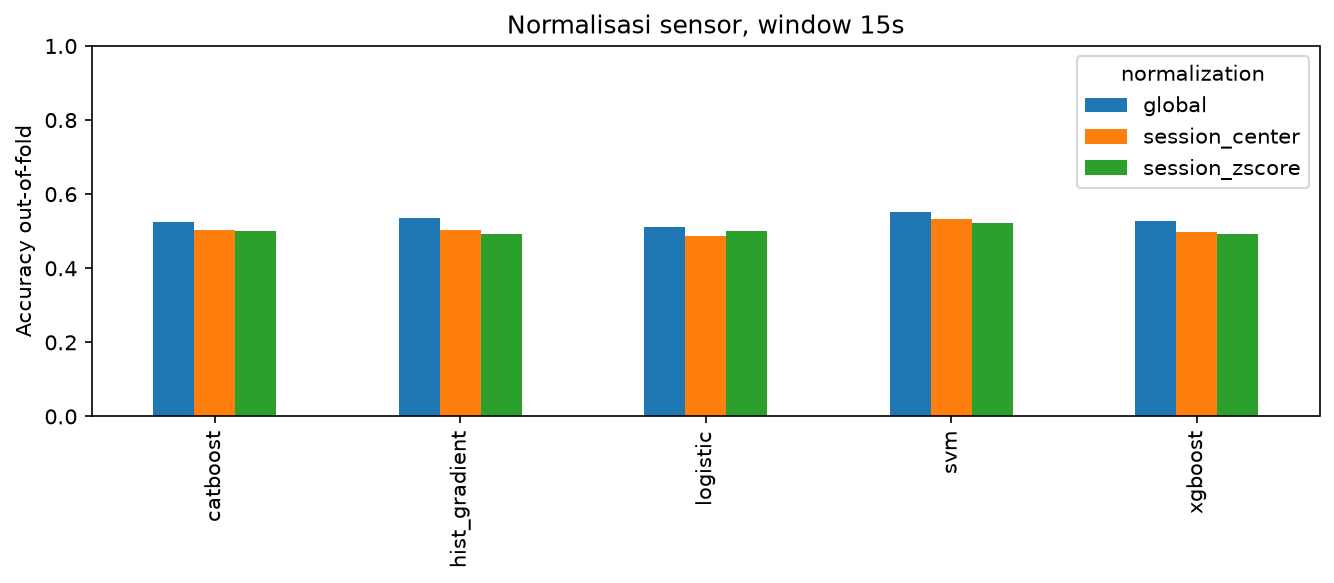

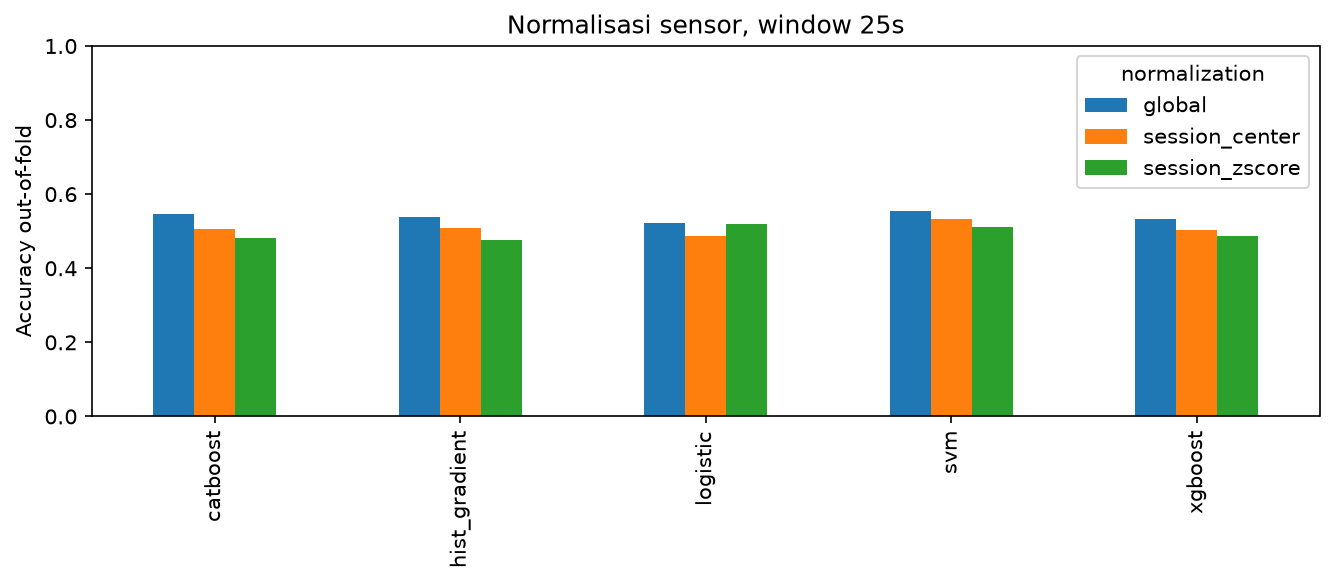

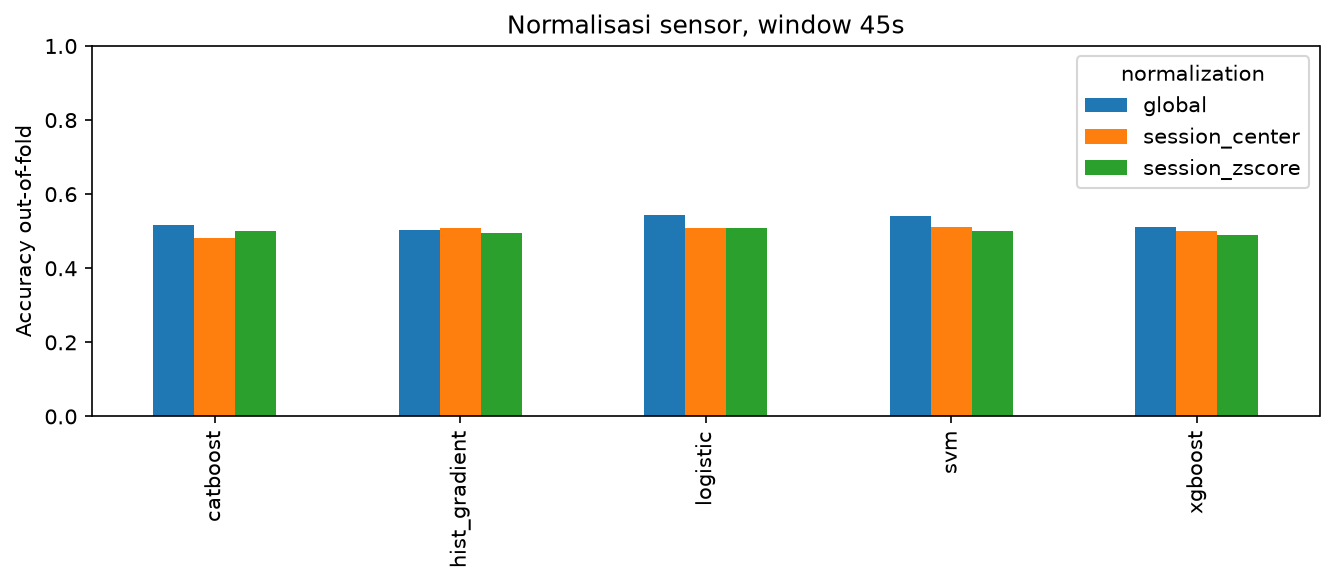

,id,window,stage,family,normalization,group,balance,accuracy,macro_f1,balanced_accuracy,accuracy_mean,accuracy_std,accuracy_min,training_accuracy,oof_rows
0,w15_eef94917981e1ac35948,15,screening,svm,global,fusion,none,0.5505,0.5511,0.5511,0.5508,0.0490,0.4844,0.8611,2069
1,w15_72574413597b3f156f7c,15,screening,hist_gradient,global,fusion,none,0.5360,0.5352,0.5347,0.5362,0.0350,0.4796,0.9218,2069
2,w15_ce0f1fc7fcaffc2c0fa1,15,screening,svm,session_center,fusion,none,0.5331,0.5301,0.5293,0.5330,0.0434,0.4693,0.8175,2069
3,w15_9089e997a3ab6fb04b8d,15,screening,svm,global,nonspatial,none,0.5278,0.5227,0.5223,0.5282,0.0470,0.4580,0.7365,2069
4,w15_d33c5e7d320470224190,15,screening,xgboost,global,fusion,none,0.5263,0.5261,0.5254,0.5265,0.0413,0.4460,0.8824,2069
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,w45_2b4158e28504f66e85ef,45,screening,xgboost,session_zscore,nonspatial,none,0.4030,0.3976,0.4008,0.4015,0.1040,0.2704,0.8229,1444
95,w45_19a8812cd407eb97b6db,45,screening,logistic,global,nonspatial,none,0.3940,0.3916,0.3924,0.3938,0.0702,0.3301,0.5303,1444
96,w45_a7a558b82f2082878020,45,screening,catboost,session_center,nonspatial,none,0.3733,0.3654,0.3708,0.3708,0.0809,0.2185,0.8095,1444
97,w45_0652dbb891655d2ee200,45,sensor_control,logistic,session_center,hrv,none,0.3269,0.3256,0.3257,0.3236,0.0668,0.2333,0.4168,1444


In [12]:
for window in (15, 25, 45):
    run_candidate(window, dummy_recipe(), "baseline")
    for family in FAMILIES:
        for normalization in NORMALIZATIONS:
            for group in ("fusion", "nonspatial"):
                recipe = base_recipe(family, normalization)
                recipe["group"] = group
                run_candidate(window, recipe, "screening")
    for group in ("eye", "hrv"):
        recipe = base_recipe("logistic", "session_center")
        recipe["group"] = group
        run_candidate(window, recipe, "sensor_control")
normalization_report(store, records)
display(validation_table(list(records.values())).round(4))

## Optimasi Konfigurasi

Pemimpin setiap normalisasi mendapat anggaran optimasi tersendiri. Fitur relatif dan balanced class weight dibandingkan sebagai konfigurasi tambahan. Class weight dihitung dari training saja. Seluruh pemilihan tahap ini menggunakan hasil internal Train; validation akhir dan test belum digunakan.

In [13]:
for window in (15, 25, 45):
    for leader in normalization_leaders(for_window(records, window)):
        for recipe in tuning_recipes(leader["recipe"]):
            run_candidate(window, recipe, "tuning")
    for leader in normalization_leaders(for_window(records, window)):
        recipe = copy.deepcopy(leader["recipe"])
        recipe["group"] = "relative"
        run_candidate(window, recipe, "relative_features")
    for leader in normalization_leaders(for_window(records, window)):
        recipe = copy.deepcopy(leader["recipe"])
        recipe["balance"] = "weight"
        run_candidate(window, recipe, "class_weight")
display(validation_table(list(records.values())).round(4))

tuning / w15_e8d14a8ab0e16dd0a446 / fold 1/5
tuning / w15_e8d14a8ab0e16dd0a446 / fold 2/5
tuning / w15_e8d14a8ab0e16dd0a446 / fold 3/5
tuning / w15_e8d14a8ab0e16dd0a446 / fold 4/5
tuning / w15_e8d14a8ab0e16dd0a446 / fold 5/5
tuning / w15_73d64ce9eb0556d108ac / fold 1/5
tuning / w15_73d64ce9eb0556d108ac / fold 2/5
tuning / w15_73d64ce9eb0556d108ac / fold 3/5
tuning / w15_73d64ce9eb0556d108ac / fold 4/5
tuning / w15_73d64ce9eb0556d108ac / fold 5/5
tuning / w15_3b9d17e786e3fb1eeff4 / fold 1/5
tuning / w15_3b9d17e786e3fb1eeff4 / fold 2/5
tuning / w15_3b9d17e786e3fb1eeff4 / fold 3/5
tuning / w15_3b9d17e786e3fb1eeff4 / fold 4/5
tuning / w15_3b9d17e786e3fb1eeff4 / fold 5/5
tuning / w15_0b406810d33b2bae6801 / fold 1/5
tuning / w15_0b406810d33b2bae6801 / fold 2/5
tuning / w15_0b406810d33b2bae6801 / fold 3/5
tuning / w15_0b406810d33b2bae6801 / fold 4/5
tuning / w15_0b406810d33b2bae6801 / fold 5/5
tuning / w15_586687bb18b5e7b9dd2e / fold 1/5
tuning / w15_586687bb18b5e7b9dd2e / fold 2/5
tuning / w

,id,window,stage,family,normalization,group,balance,accuracy,macro_f1,balanced_accuracy,accuracy_mean,accuracy_std,accuracy_min,training_accuracy,oof_rows
0,w15_4c8d5f636b839c01e0ba,15,relative_features,svm,global,relative,none,0.5631,0.5626,0.5626,0.5633,0.0476,0.5084,0.8671,2069
1,w15_8b7f5537af20e7e1aa26,15,class_weight,svm,global,relative,weight,0.5621,0.5619,0.5642,0.5624,0.0591,0.4868,0.8617,2069
2,w15_eef94917981e1ac35948,15,screening,svm,global,fusion,none,0.5505,0.5511,0.5511,0.5508,0.0490,0.4844,0.8611,2069
3,w15_72574413597b3f156f7c,15,screening,hist_gradient,global,fusion,none,0.5360,0.5352,0.5347,0.5362,0.0350,0.4796,0.9218,2069
4,w15_ce0f1fc7fcaffc2c0fa1,15,screening,svm,session_center,fusion,none,0.5331,0.5301,0.5293,0.5330,0.0434,0.4693,0.8175,2069
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
146,w45_19a8812cd407eb97b6db,45,screening,logistic,global,nonspatial,none,0.3940,0.3916,0.3924,0.3938,0.0702,0.3301,0.5303,1444
147,w45_a7a558b82f2082878020,45,screening,catboost,session_center,nonspatial,none,0.3733,0.3654,0.3708,0.3708,0.0809,0.2185,0.8095,1444
148,w45_82a7a877ffeea61c4fb0,45,tuning,svm,global,nonspatial,none,0.3553,0.3458,0.3524,0.3569,0.0665,0.2857,0.5704,1444
149,w45_0652dbb891655d2ee200,45,sensor_control,logistic,session_center,hrv,none,0.3269,0.3256,0.3257,0.3236,0.0668,0.2333,0.4168,1444


## Seleksi Model Akhir

Maksimal dua keluarga berbeda per normalisasi dilatih pada seluruh Train. Model individual dibandingkan dengan hard voting serta rata-rata probabilitas kandidat yang mendukungnya. Anggota ensemble ditentukan dari peringkat out-of-fold sebelum melihat validation akhir.

Accuracy validation akhir menjadi kriteria utama, diikuti Macro-F1, minimum accuracy fold internal, jumlah komponen, dan jumlah fitur. Bentuk model individual atau ensemble yang akan disimpan dinilai langsung pada tahap ini.

In [14]:
finalists = fit_finalists(store, views, records, fit_tabular, predict_tabular)
display(
    pd.DataFrame(
        [
            {"window": r["window"], "id": r["id"], "kind": r["kind"], **r["validation"]}
            for r in finalists
        ]
    ).round(4)
)

Fitting seluruh Train / w15_4c8d5f636b839c01e0ba / seed 42
Fitting seluruh Train / w15_72574413597b3f156f7c / seed 42
Fitting seluruh Train / w15_ce0f1fc7fcaffc2c0fa1 / seed 42
Fitting seluruh Train / w15_7421c0fc85d848e6db09 / seed 42
Fitting seluruh Train / w15_4f911680ce5738c753bb / seed 42
Fitting seluruh Train / w15_b1fad598cb280e7602e5 / seed 42
Fitting seluruh Train / w25_8b7f5537af20e7e1aa26 / seed 42
Fitting seluruh Train / w25_4f7b17d6e72bc66340f5 / seed 42
Fitting seluruh Train / w25_ce0f1fc7fcaffc2c0fa1 / seed 42
Fitting seluruh Train / w25_4f6fc32d94816f19b92f / seed 42
Fitting seluruh Train / w25_7421c0fc85d848e6db09 / seed 42
Fitting seluruh Train / w25_9efb378af0c04468e158 / seed 42
Fitting seluruh Train / w45_4b4b383ebb710e5f5a64 / seed 42
Fitting seluruh Train / w45_b153698406cd7b47d621 / seed 42
Fitting seluruh Train / w45_f86eb5b6da7a83096020 / seed 42
Fitting seluruh Train / w45_bec9fc392c0ad1824d74 / seed 42
Fitting seluruh Train / w45_9efb378af0c04468e158 / seed 

,id,window,kind,components,parents,accuracy,macro_f1,balanced_accuracy,training_accuracy,inner_min_accuracy,features
0,selection_w15_cd0712e0b9959ff682bb,15,single,1,w15_72574413597b3f156f7c,0.6107,0.6107,0.6081,0.8898,0.4796,23
1,selection_w15_af373fbb10ddf5446b36,15,vote,3,w15_4c8d5f636b839c01e0ba;w15_72574413597b3f156...,0.6018,0.6012,0.6015,0.9009,0.4693,27
2,selection_w15_5751d063fc0e96cc61bb,15,single,1,w15_4c8d5f636b839c01e0ba,0.5982,0.5990,0.5988,0.8594,0.5084,27
3,selection_w15_4a07c72c8571f8d32603,15,probability_average,3,w15_72574413597b3f156f7c;w15_4f911680ce5738c75...,0.5768,0.5717,0.5708,0.8850,0.4619,23
4,selection_w15_d699f92f6f13ad3edead,15,single,1,w15_7421c0fc85d848e6db09,0.4875,0.4853,0.4826,0.8168,0.4496,23
5,selection_w15_9a69d12a4ce6d77c1128,15,single,1,w15_b1fad598cb280e7602e5,0.4821,0.4757,0.4746,0.7409,0.4619,23
6,selection_w15_2430d73a4edc13b6e208,15,single,1,w15_ce0f1fc7fcaffc2c0fa1,0.4768,0.4683,0.4700,0.8091,0.4693,23
7,selection_w15_03a6615d3a7869e216e5,15,single,1,w15_4f911680ce5738c753bb,0.4482,0.4391,0.4410,0.7574,0.4742,23
8,selection_w25_88b6c8fb15e3fcf08fcb,25,single,1,w25_8b7f5537af20e7e1aa26,0.6258,0.6184,0.6203,0.8949,0.4960,27
9,selection_w25_58d4a8da4d1eb917ebd8,25,vote,3,w25_8b7f5537af20e7e1aa26;w25_4f7b17d6e72bc6634...,0.6217,0.6145,0.6151,0.9149,0.4263,27


,window,id,kind,accuracy,macro_f1,balanced_accuracy
0,15,selection_w15_cd0712e0b9959ff682bb,single,0.6107,0.6107,0.6081
1,25,selection_w25_88b6c8fb15e3fcf08fcb,single,0.6258,0.6184,0.6203
2,45,selection_w45_973cfcfe187dedd47342,vote,0.5362,0.5224,0.5204


## Evaluasi Test

Pilihan per-window dan model utama dikunci dari validation akhir sebelum test dibuka. Model test identik dengan model pada seleksi akhir, tanpa fitting ulang. Classification report dan confusion matrix memperlihatkan precision, recall, dan F1 tiap kelas. Hasil out-of-fold, validation akhir, dan test dilaporkan terpisah.

Window 15s: test accuracy=45.91%, Macro-F1=44.86%


,precision,recall,f1-score,support
Low,0.4095,0.3050,0.3496,141.0000
Medium,0.4667,0.4451,0.4556,173.0000
High,0.4794,0.6200,0.5407,150.0000
accuracy,0.4591,0.4591,0.4591,0.4591
macro avg,0.4519,0.4567,0.4486,464.0000
weighted avg,0.4534,0.4591,0.4509,464.0000


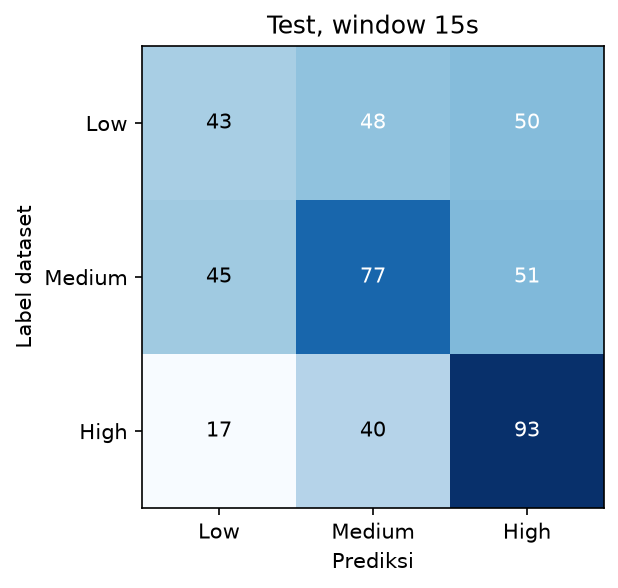

Window 25s: test accuracy=42.08%, Macro-F1=40.87%


,precision,recall,f1-score,support
Low,0.3942,0.3083,0.3460,133.0000
Medium,0.4196,0.2919,0.3443,161.0000
High,0.4348,0.6977,0.5357,129.0000
accuracy,0.4208,0.4208,0.4208,0.4208
macro avg,0.4162,0.4326,0.4087,423.0000
weighted avg,0.4163,0.4208,0.4032,423.0000


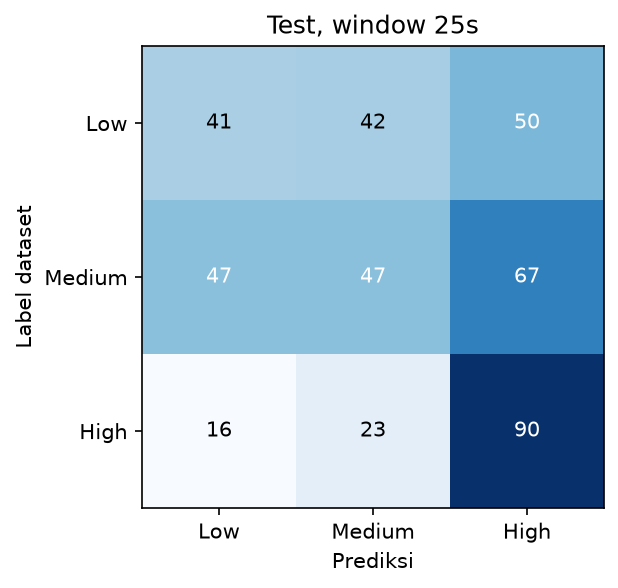

Window 45s: test accuracy=38.46%, Macro-F1=37.33%


,precision,recall,f1-score,support
Low,0.4597,0.4560,0.4578,125.0000
Medium,0.2045,0.1636,0.1818,110.0000
High,0.4365,0.5340,0.4803,103.0000
accuracy,0.3846,0.3846,0.3846,0.3846
macro avg,0.3669,0.3845,0.3733,338.0000
weighted avg,0.3696,0.3846,0.3749,338.0000


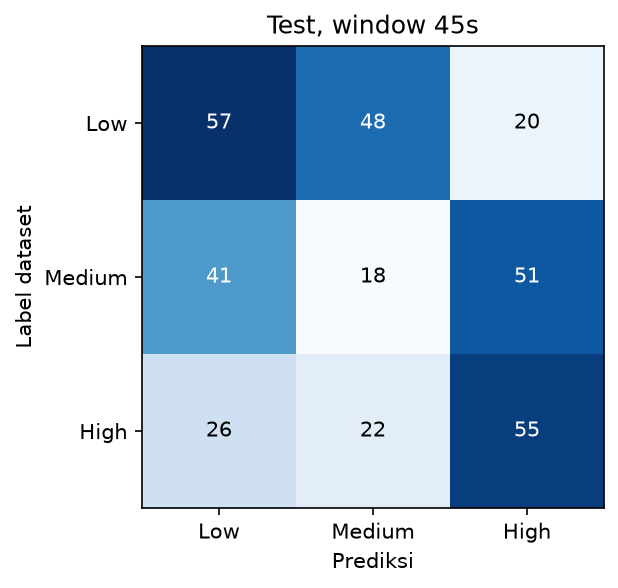

# Hasil Batch-04

Model utama: window 25 detik, dipilih dari validation akhir.

- Accuracy test: 42.08%
- Macro-F1 test: 40.87%
- Balanced accuracy test: 43.26%

Model test identik dengan model pada validation akhir. Tidak ada refit setelah seleksi. Evaluasi internal memakai blok waktu campuran dengan purge 45 detik. Dataset dan test pernah digunakan pada eksperimen terdahulu.

Model: final_selection_w25_88b6c8fb15e3fcf08fcb/model.pkl. Jenis skor: decision_score.



,window,primary,test_rows,training_accuracy,selection_accuracy,selection_macro_f1,accuracy,macro_f1,balanced_accuracy
0,15,False,464,0.8898,0.6107,0.6107,0.4591,0.4486,0.4567
1,25,True,423,0.8949,0.6258,0.6184,0.4208,0.4087,0.4326
2,45,False,338,0.8206,0.5362,0.5224,0.3846,0.3733,0.3845


In [15]:
test_summary = final_evaluation(store, views, finalists, predict_tabular)
display(test_summary.round(4))

## Prediksi dengan Model Tersimpan

Bundle memuat classifier, urutan fitur, preprocessing, dan acuan normalisasi training. Metadata sesi digunakan untuk memilih acuan, bukan sebagai predictor. Gunakan hanya artefak model yang terpercaya.

In [16]:
selected = store.read("selection")
model = load_bundle(store.artifact("final_" + selected["primary_id"], "model.pkl"))
example = outer_frame(views[selected["primary_window"]], "test").head(3)
prediction = predict_tabular(model, example)
display(
    pd.DataFrame(
        {
            "label": np.asarray(LABELS)[prediction["labels"]],
            **{
                f"{prediction['score_type']}_{label}": prediction["scores"][:, i]
                for i, label in enumerate(LABELS)
            },
        }
    )
)

,label,decision_score_Low,decision_score_Medium,decision_score_High
0,Low,2.112537,1.034215,-0.128088
1,Medium,0.917679,2.194214,-0.172152
2,Medium,1.062634,2.228880,-0.235942
